In [1]:
import sys
sys.path.append("..")

In [2]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))
print(torch.cuda.get_device_properties(0).total_memory / 1024**3)

True
NVIDIA A100-SXM4-40GB
39.4935302734375


In [2]:
import h5py
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from utils.das_dataset import DasDataset
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm
from utils.noise_scheduler import LinearNoiseScheduler 
from IPython.display import clear_output

**Model 2 : Earthquake Baseline 1001 :**
*standard shuffled loader*
**unet_model_ssa**

In [3]:
das_data = Path("/datasets/training/earthquake/share/SISSLE_south30")
train_files_earthquake = [das_data/"train_1001.h5"]
test_files_earthquake = [das_data/"test_1001.h5"]

device= "cuda" if torch.cuda.is_available() else "cpu"

train_set_earthquake = DasDataset(train_files_earthquake)
test_set_earthquake = DasDataset(test_files_earthquake)
train_loader_earthquake = DataLoader(train_set_earthquake, batch_size=16, shuffle=True)
test_loader_earthquake = DataLoader(test_set_earthquake, batch_size=16, shuffle=False)

In [7]:
from models.unet_ssa import DDPM
model_earthquake_ssa =  DDPM(in_channels=1, out_channels=1, base_channels=64, channels_multiplier=(1,1,2,2,4),
                  nbr_rb=2, dropout=0.1).to(device)

In [8]:
x_E = next(iter(train_loader_earthquake)).to(device)
scheduler_E = LinearNoiseScheduler(timesteps=1000, beta_start=1e-4,beta_end=0.02, device=device)
t = torch.randint(0,scheduler_E.betas.shape[0], (x_E.shape[0],), device= device).long()
with torch.no_grad():
    noise_prediction_E = model_earthquake_ssa(x_E,t)
print("shape of input: ", x_E.shape)
print("shape of output: ", noise_prediction_E.shape)

shape of input:  torch.Size([16, 1, 256, 512])
shape of output:  torch.Size([16, 1, 256, 512])


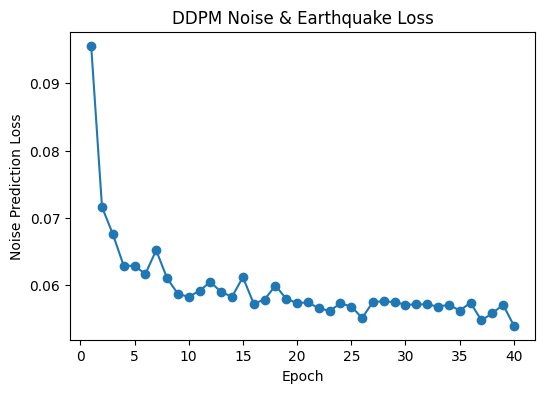

In [10]:
checkpoints=Path("checkpoints")
checkpoints.mkdir(exist_ok=True)
model_earthquake_path=checkpoints/"das_ddpm_earthquake_model_ssa.pth"
earthquake_loss_plot_path=checkpoints/"das_ddpm_earthquake_loss_ssa.png"

optimizer_earthquake_ssa= torch.optim.Adam(model_earthquake_ssa.parameters(), lr=1e-4)

epochs_earthquake= 40 
earthquake_train_losses=[]
earthquake_start_epoch=0


if model_earthquake_path.exists():
    checkpoint = torch.load(model_earthquake_path,map_location=device)
    if "model_earthquake_ssa" in checkpoint:
        model_earthquake_ssa.load_state_dict(checkpoint["model_earthquake_ssa"])
    if "optimizer_earthquake_ssa" in checkpoint:
        optimizer_earthquake_ssa.load_state_dict(checkpoint["optimizer_earthquake_ssa"])
    earthquake_train_losses= checkpoint.get("earthquake_train_losses", [])
    earthquake_start_epoch=checkpoint.get("completed_epochs", len(earthquake_train_losses)) 

for epoch in range(earthquake_start_epoch, epochs_earthquake):

    model_earthquake_ssa.train()
    epoch_loss= 0.0

    for batch in tqdm(train_loader_earthquake, desc=f"Epoch{epoch+1}/{epochs_earthquake}"):

        x=batch.to(device)
        epsilon=torch.randn_like(x)
        t=torch.randint(0,scheduler_E.betas.shape[0],(x.shape[0],),device=device).long()
        xt=scheduler_E.add_noise(x0=x, epsilon=epsilon,t=t)
        noise_prediction=model_earthquake_ssa(xt,t)
        
        loss=((noise_prediction -epsilon)**2).mean()

        optimizer_earthquake_ssa.zero_grad()
        loss.backward()
        optimizer_earthquake_ssa.step()
        epoch_loss+= loss.item()

    avg_loss=epoch_loss/len(train_loader_earthquake)
    earthquake_train_losses.append(avg_loss)
   
    torch.save({
    "model_earthquake_ssa": model_earthquake_ssa.state_dict(), "optimizer_earthquake_ssa": optimizer_earthquake_ssa.state_dict(),"earthquake_train_losses":earthquake_train_losses,
                  "completed_epochs": epoch+1, "base_channels": 64, "channels_multipilier": ( 1,1,2,2,4),
                  "normalizartion": {"function": "arcsinh", "s": 50.0, "A_max": 12350.0}
     }, model_earthquake_path)
    
    clear_output(wait =  True)
    plt.figure(figsize = (6,4))
    plt.plot(range(1,len(earthquake_train_losses)+1), earthquake_train_losses, marker="o")
    plt.xlabel("Epoch")
    plt.ylabel("Noise Prediction Loss")
    plt.title("DDPM Noise & Earthquake Loss")
    plt.savefig(earthquake_loss_plot_path)
    plt.show() 


In [11]:
checkpoint_earthquake_ssa = torch.load(model_earthquake_path, map_location = device)
model_earthquake_ssa.load_state_dict(checkpoint_earthquake_ssa["model_earthquake_ssa"])
model_earthquake = model_earthquake_ssa.to(device)

In [12]:
num_images = 2
xt = torch.randn(num_images, 1,256,512, device = device)
print(xt.shape)
timesteps_shown = [999, 600 , 300, 100, 0]

torch.Size([2, 1, 256, 512])


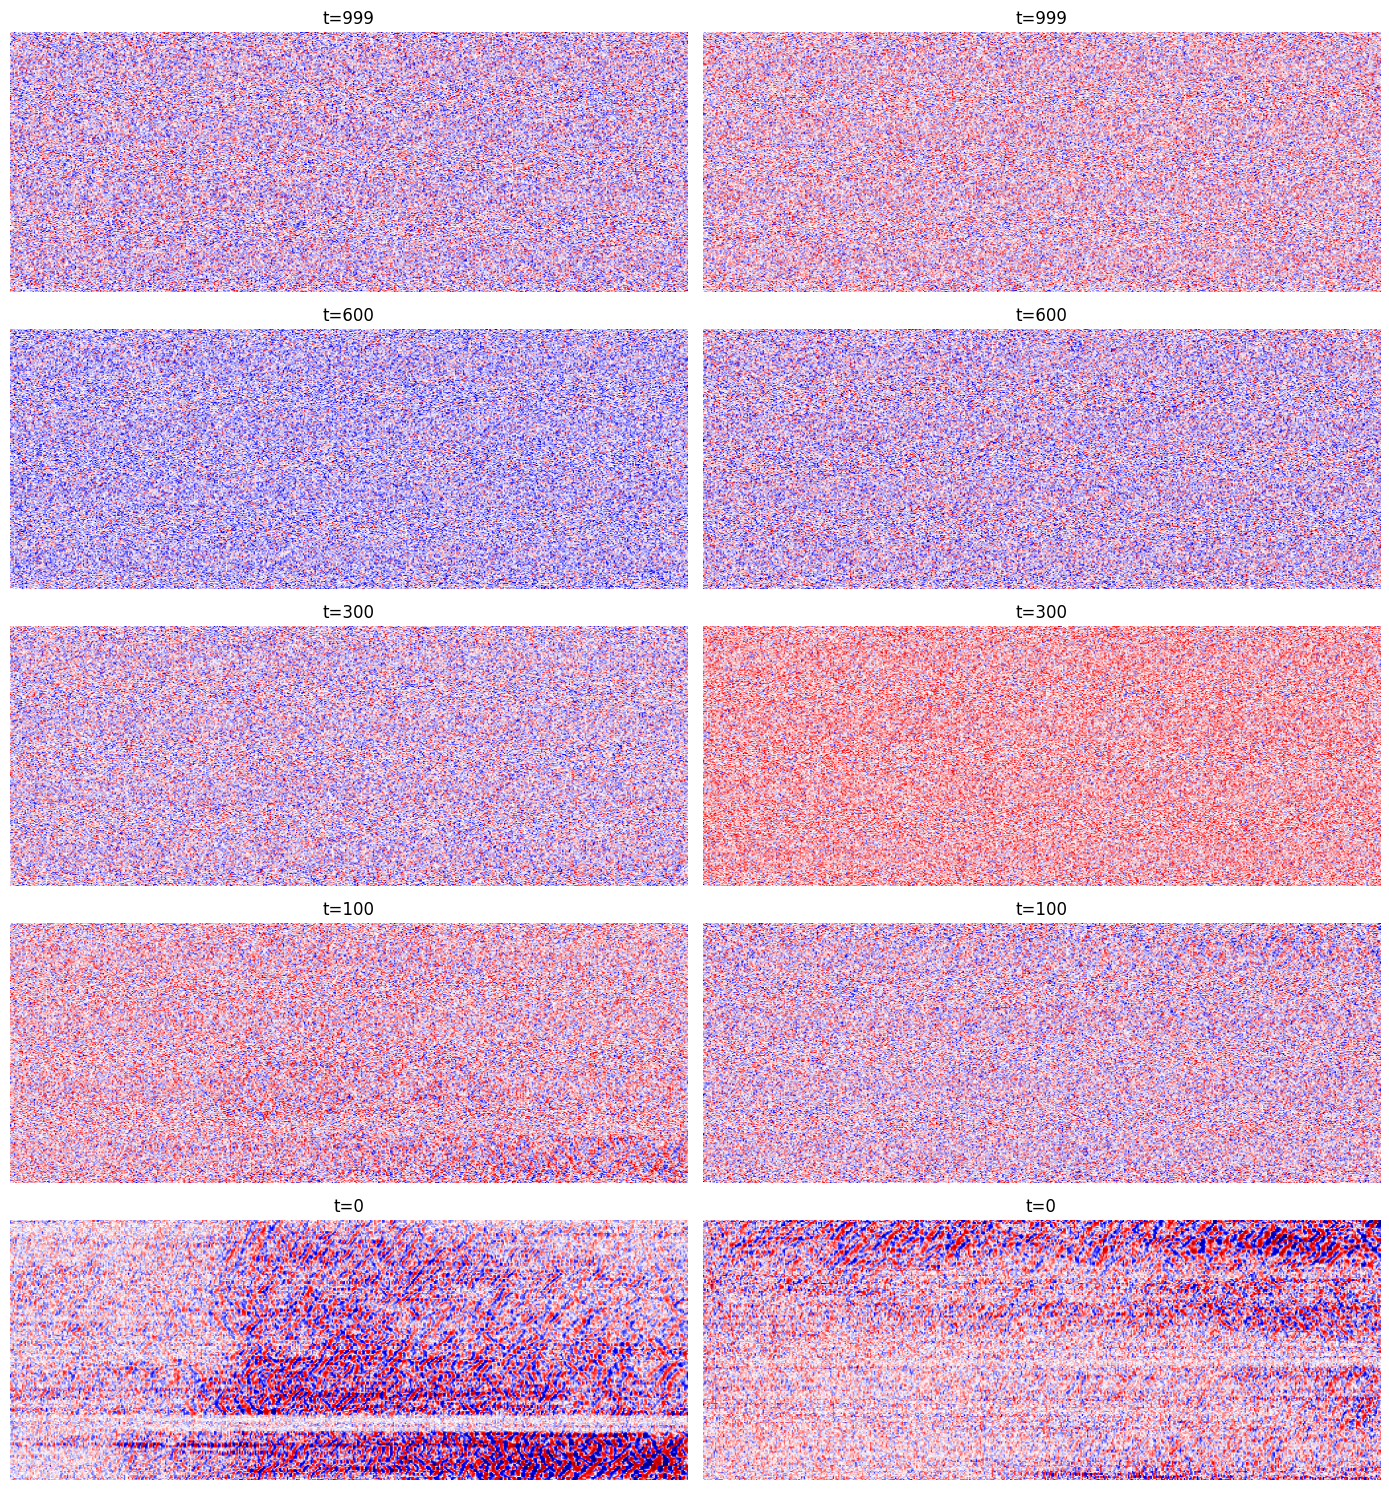

In [13]:
num_rows = len(timesteps_shown)
fig2, axes2 = plt.subplots(num_rows, num_images, figsize = (7*num_images, 3*num_rows))
model_earthquake_ssa.eval()
with torch.no_grad():
    for step in reversed(range(scheduler_E.betas.shape[0])):
        if step in timesteps_shown:
            row= timesteps_shown.index(step)
            for i in range(num_images):
                axes2[row,i].imshow(xt[i,0].detach().cpu(), aspect="auto", cmap="seismic") 
                axes2[row,i].axis("off")
                axes2[row,i].set_title(f"t={step}")
        t=torch.full((num_images,),step, device=device, dtype= torch.long)
        predicted_noise=model_earthquake_ssa(xt,t)
        xt,x0_predicted=scheduler_E.reverse_sampling_step(xt,predicted_noise,step)
plt.tight_layout()
plt.show()

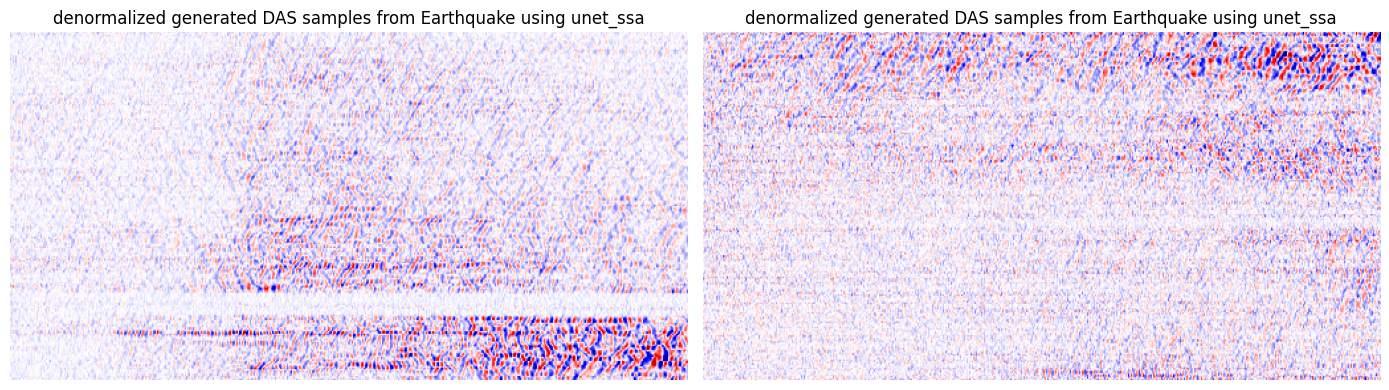

In [14]:
from utils.normalizer import denormalize
denormalized = denormalize(xt)
fig3, axes3 = plt.subplots(1, num_images, figsize = (7*num_images,4))
for i in range(num_images):
                axes3[i].imshow(denormalized[i,0].detach().cpu(), aspect="auto", cmap="seismic" ) 
                axes3[i].axis("off")
                axes3[i].set_title("denormalized generated DAS samples from Earthquake using unet_ssa")
plt.tight_layout()
plt.show()    

In [15]:
percentiles=[50,60,99,99.9,99.99]
#normalized
x_test_e = next(iter(test_loader_earthquake))[:num_images].to(device)
#denomalized
x_test_e = denormalize(x_test_e).detach().cpu().numpy()
denormalized_tensor_e = denormalize(xt[:num_images])
denormalized_tensor_e= denormalized_tensor_e[:num_images].detach().cpu().numpy()

x_test_percentiles_e = np.percentile(np.abs(x_test_e).reshape(-1), percentiles)
denormalized_percentiles_e = np.percentile(np.abs(denormalized_tensor_e).reshape(-1), percentiles)

for i in range (len(percentiles)):
    print(
        f"{percentiles[i]}% |" f" real DAS Earthquakes: {x_test_percentiles_e[i]:.2f} |" f" generated DAS Earthquake {denormalized_percentiles_e[i]:.2f}"
    )

50% | real DAS Earthquakes: 37.51 | generated DAS Earthquake 31.81
60% | real DAS Earthquakes: 48.06 | generated DAS Earthquake 41.14
99% | real DAS Earthquakes: 315.15 | generated DAS Earthquake 290.56
99.9% | real DAS Earthquakes: 778.26 | generated DAS Earthquake 520.23
99.99% | real DAS Earthquakes: 1102.59 | generated DAS Earthquake 716.32
